# Session 8 Notebook - Multi-Dimensional Data

In [1]:
from matplotlib import pyplot
import seaborn
import pandas
import nibabel
import scipy.signal
import numpy
import spacemed

In [2]:
!pwd

/home/olso13/SpaceMed-2026/olso13/notebooks


In [3]:
anatomy = nibabel.load("../data/fmri-data/2_Anatomy_1mm_5min.nii")

In [4]:
print(anatomy.header) # Metadata of the dataset

<class 'nibabel.nifti1.Nifti1Header'> object, endian='<'
sizeof_hdr      : 348
data_type       : b''
db_name         : b''
extents         : 0
session_error   : 0
regular         : b'r'
dim_info        : 54
dim             : [  3 192 256 256   1   1   1   1]
intent_p1       : 0.0
intent_p2       : 0.0
intent_p3       : 0.0
intent_code     : none
datatype        : int16
bitpix          : 16
slice_start     : 0
pixdim          : [1.       1.       0.976562 0.976562 2.3      0.       0.       0.      ]
vox_offset      : 0.0
scl_slope       : nan
scl_inter       : nan
slice_end       : 0
slice_code      : unknown
xyzt_units      : 10
cal_max         : 0.0
cal_min         : 0.0
slice_duration  : 0.0
toffset         : 0.0
glmax           : 0
glmin           : 0
descrip         : b'TE=2.3;Time=170738.945'
aux_file        : b''
qform_code      : scanner
sform_code      : scanner
quatern_b       : -0.027891552075743675
quatern_c       : 0.006216157227754593
quatern_d       : -0.0195028111338615

In [5]:
print(anatomy.shape) # Size of the dataset (no of slices)

(192, 256, 256)


In [6]:
print(anatomy.header.get_zooms()) # Voxel sizes (scanner left-right; scanner floor-ceiling; scanner bore)

(np.float32(1.0), np.float32(0.976562), np.float32(0.976562))


[coordinate system](https://nipy.org/nibabel/coordinate_systems.html)

In [7]:
data_anatomy = anatomy.get_fdata() 

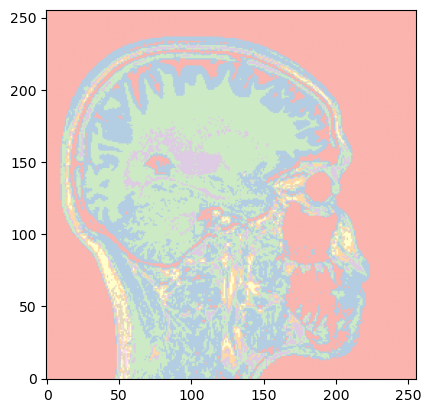

In [8]:
fig, axes = pyplot.subplots(1)
axes.imshow(data_anatomy[120, :, :].T,
origin="lower",
cmap="Pastel1")

#Change indices, change position --> [frontal, horizontal, sagittal]

#'.T' transposes to rows and columns, origin = "lower" places the origin in the bottom left, convention in neuroimaging

In [9]:
print(anatomy.affine) # When comparing datasets --> transform one to the coordinate system of the other via rotation and translation). ".affine" finds the transformation matrix

[[ 9.99162018e-01  3.77299786e-02  1.31960846e-02 -9.83170929e+01]
 [-3.93290296e-02  9.74299788e-01  5.42062148e-02 -1.24112167e+02]
 [-1.13369459e-02 -5.46798818e-02  9.74967122e-01 -1.17133888e+02]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


In [10]:
ols = pandas.read_csv("../data/ols.csv") # Orbital Launch System data

[Seaborn](https://seaborn.pydata.org/) is a visualization library. Does nice plots essentially, still need to run stats separately. 

In [11]:
ols

,Vehicle,Length (m),Payload Mass to LEO (kg),Origin,First Flight,Initial Mass (kg)
0,Falcon 9,70.00,22800,USA,2010.0,549000
1,Falcon Heavy,70.00,63800,USA,2018.0,1420000
2,Atlas V,62.50,13550,USA,2002.0,335000
3,Delta IV Heavy,72.00,28370,USA,2002.0,733000
4,SLS Block 1,98.00,95000,USA,2022.0,2600000
5,Starship,120.00,125000,USA,2024.0,5000000
6,Vulcan Centaur,61.00,27200,USA,2023.0,540000
7,Electron,18.00,300,USA,2015.0,12500
8,New Glenn,98.00,45000,USA,2021.0,862000
9,Saturn V,110.60,140000,USA,1967.0,3000000


<Axes: xlabel='Initial Mass (kg)', ylabel='Payload Mass to LEO (kg)'>

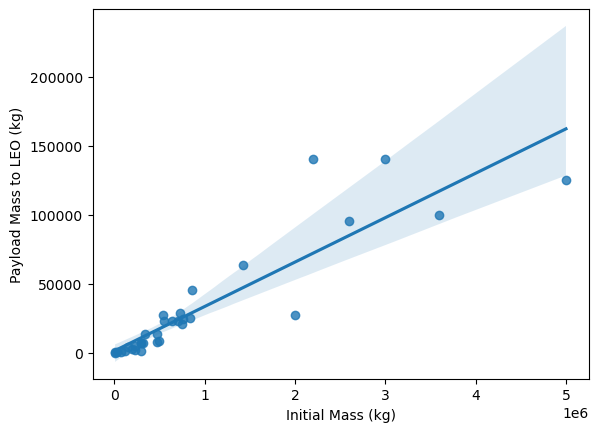

In [12]:
seaborn.regplot(ols,
                x="Initial Mass (kg)",
                y="Payload Mass to LEO (kg)",
                order=1)

#"regplot" correlation visuals

<Axes: xlabel='Length (m)', ylabel='Payload Mass to LEO (kg)'>

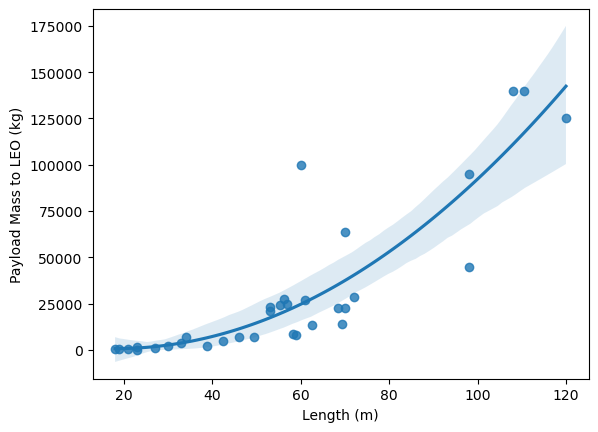

In [13]:
seaborn.regplot(ols,
                x="Length (m)",
                y="Payload Mass to LEO (kg)",
                order=2)
# changing the order of a fit

## fMRI
**Objective** : Create image showing activated regions of the brain during fMRI (doing a cross correlation)

In [14]:
fmri = nibabel.load("../data/fmri-data/3_fMRI_TR2sec_3mm_3min.nii")

In [15]:
fmri.shape

(64, 64, 32, 80)

In [16]:
print(fmri.header.get_zooms())

(np.float32(3.0), np.float32(3.0), np.float32(3.75), np.float32(2.0))


In [17]:
nt = fmri.shape[-1] # nt is number of time samples, so 80 of them and 2s each

In [18]:
sampling_rate = fmri.header.get_zooms()[-1]

In [19]:
print(nt, sampling_rate) # 10 seconds on, followed by a period of 10s off

80 2.0


In [20]:
p1 = (19,24,25) # 3 points within the volume as seen previously (voxel coordinates)
p2 = (40,25,25)
p3 = (19,25,25)

In [21]:
fmri_data = fmri.get_fdata()

In [22]:
fmri_data[p1] # array with p1 across all the time series, since it's a point in a 4d environment

array([406., 403., 433., 477., 506., 511., 514., 522., 515., 496., 454.,
       435., 435., 457., 466., 475., 476., 477., 461., 431., 425., 417.,
       441., 471., 487., 495., 501., 503., 479., 432., 376., 362., 414.,
       460., 465., 473., 471., 476., 455., 408., 385., 386., 410., 460.,
       482., 501., 510., 498., 464., 420., 429., 406., 410., 455., 475.,
       491., 481., 457., 455., 415., 402., 386., 419., 452., 479., 484.,
       482., 476., 447., 403., 380., 376., 414., 468., 491., 488., 488.,
       495., 495., 475.])

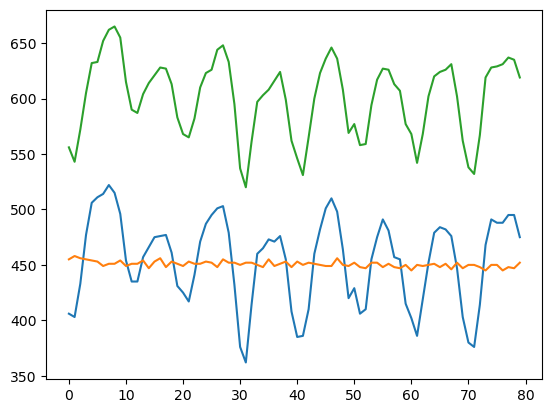

In [23]:
pyplot.plot(fmri_data[p1]) # Plotting a time series with all three points (raw output)
pyplot.plot(fmri_data[p2])
pyplot.plot(fmri_data[p3])

In [24]:
s_one = numpy.array([1]*5 + [0]*5) # creating the signal essentially, 10S [1] on and 10s [0] off, sampling rate every 2s, so 5 since 5*2=10

In [25]:
s_one

array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0])

In [26]:
numpy.tile(s_one, 2) # running it twice essentially

array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0])

In [27]:
signal = numpy.tile(s_one, int(numpy.ceil(nt/10))) # Since we need 80 samples, we need to modify the array to fit with the numpy.ceiling
signal = signal[:nt] # clip it at the end in the case of division problem

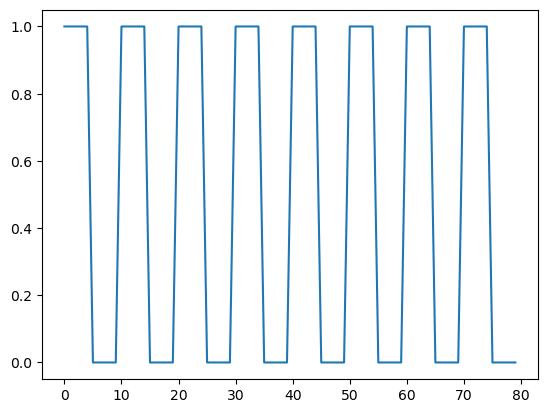

In [28]:
pyplot.plot(signal) # visualise

In [29]:
def normalise(data): # function to normalise the data from the 3 time series (subtracting the mean of curve from data, then dividing by standard deviation)
    norm = (data - numpy.mean(data)) # substract the mean from every curve and divide from SD which normalizes the amplitude
    norm = norm / numpy.std(data)
    return norm

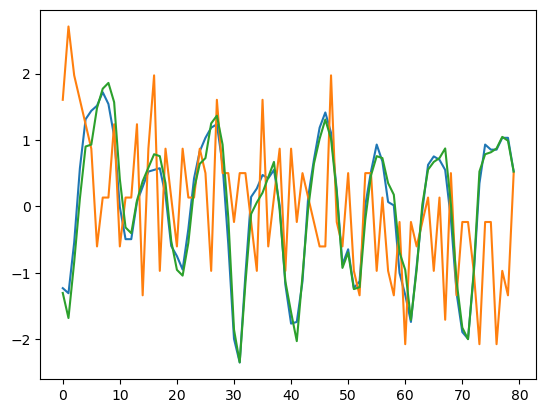

In [30]:
pyplot.plot(normalise(fmri_data[p1]))  # plot normalised data
pyplot.plot(normalise(fmri_data[p2]))
pyplot.plot(normalise(fmri_data[p3]))

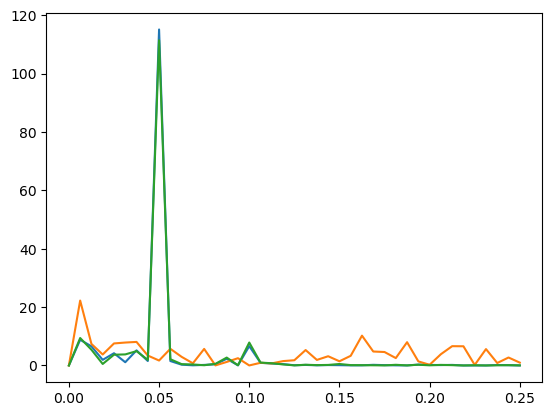

In [31]:
for p in [p1, p2, p3]: # Periodogram looks at power distribution across frequencies makes me think of FFT (you can see spikes in certain points)
    freq, power = scipy.signal.periodogram(normalise(fmri_data[p]), # Using for loop to do all 3 points
                                       fs=1/sampling_rate)
    pyplot.plot(freq, power)

Spike at 0.05 corresponds to our 20 second sampling setup (10s on and 10s off)

58.11914196096052
11.543840394935287
56.45565951227974


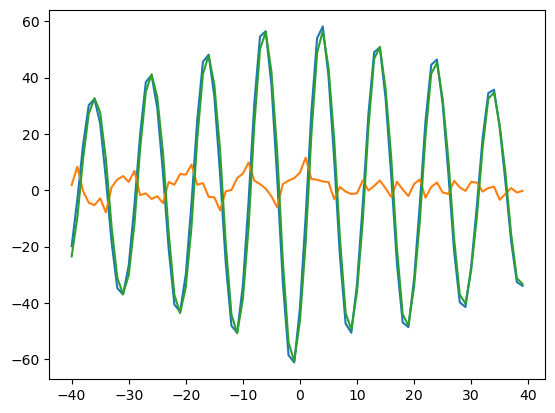

In [32]:
for p in [p1, p2, p3]: # find cross correlation for all points
    data = fmri_data[p]
    cross = scipy.signal.correlate(  #finding maximum for the cross correlation
        normalise(data), normalise(signal),
        mode="same")
    lags = scipy.signal.correlation_lags( # "interesting response" 8 seconds after stimulus, called lag here. Need to take into account
        len(data), len(signal),
        mode="same")
    pyplot.plot(lags, cross)
    c = numpy.max(cross)
    print(c) # c is cross correlation value

In [33]:
numpy.zeros(fmri.shape[:2]) # you have a loop storing stuff in this array, nested loop ? 

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(64, 64))

# Exercise
1. Add function to spacemed module that computes the
cross correlation given the input signal and the fMRI
output and a voxel index

2. Add program that computes the cross correlation for one
slice and displays the data with command line arguments
• name of fMRI file
• the slice to process (an integer)
• the name of the output image file

## 1. Cross correlation function

In [34]:
spacemed.cross_corr(signal, fmri_data, p1)

(array([-40, -39, -38, -37, -36, -35, -34, -33, -32, -31, -30, -29, -28,
        -27, -26, -25, -24, -23, -22, -21, -20, -19, -18, -17, -16, -15,
        -14, -13, -12, -11, -10,  -9,  -8,  -7,  -6,  -5,  -4,  -3,  -2,
         -1,   0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,
         12,  13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,
         25,  26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,
         38,  39]),
 array([-19.86957468,  -3.19573233,  16.09855329,  30.20283476,
         32.34975375,  23.65872292,   4.03370175, -18.41529227,
        -34.75839906, -37.00708284, -26.73869781,  -5.28191046,
         19.81296801,  38.39490012,  40.87255467,  29.20490382,
          6.17076228, -20.83220596, -40.60987431, -43.08752886,
        -29.8934062 ,  -4.59499815,  24.82488378,  45.56931761,
         48.12329575,  33.3009365 ,   5.91635031, -25.94588651,
        -48.14046856, -50.56724071, -33.81135051,  -3.78087985,
         30.77812382,  54.5500

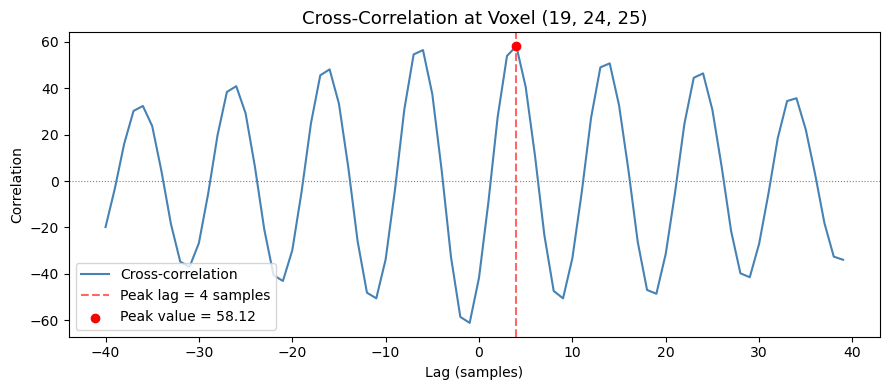

Voxel           : (19, 24, 25)
Peak correlation: 58.1191
Peak lag        : 4 samples


In [36]:
spacemed.plot_cross_corr(*spacemed.cross_corr(signal, fmri_data, p1), p1)

## 2 Cross correlation for a single slice program

In [ ]:
# below is an in depth explanation of the program to generate the activation slice
# The  program itself is in the setup.cfg and runs in the console (just want to keep this here for reference)

def build_activation_map(fmri_file, slice_index, output_file):
    """
    Core computation: load fMRI data, build activation map, save image.

    This function contains all the science.  `main()` below is just the
    command-line wrapper that parses arguments and calls this function.

    Parameters
    ----------
    fmri_file   : str   – path to the NIfTI (.nii / .nii.gz) file
    slice_index : int   – which z-slice to process (0-based index)
    output_file : str   – filename for the saved PNG image

    Returns
    -------
    corr_mat : 2-D numpy array
        The activation map (peak cross-correlation per voxel).
    """

    # ── 1. Load the fMRI file ────────────────────────────────────────────────
    print(f"Loading: {fmri_file}")
    img  = nibabel.load(fmri_file)
    data = img.get_fdata()

    nt = data.shape[-1]              # number of time points
    TR = img.header.get_zooms()[-1]  # repetition time in seconds

    # Validate that the requested slice actually exists
    n_slices = data.shape[2]
    if not (0 <= slice_index < n_slices):
        raise ValueError(
            f"slice_index {slice_index} is out of range. "
            f"This file has {n_slices} slices (0 – {n_slices-1})."
        )

    print(f"Data shape : {data.shape}  (x, y, z, time)")
    print(f"TR = {TR} s   |   nt = {nt}   |   Processing slice z = {slice_index}")

    # ── 2. Build the stimulus signal ─────────────────────────────────────────
    # 10 s ON → 5 samples (at TR=2 s), 10 s OFF → 5 samples, repeated.
    # numpy.tile repeats the pattern; we clip to exactly nt.
    one_cycle = numpy.array([1] * 5 + [0] * 5)
    signal    = numpy.tile(one_cycle, int(numpy.ceil(nt / 10)))[:nt]

    # ── 3. Build the correlation matrix ──────────────────────────────────────
    # We create a 2-D array of zeros with the same (x, y) dimensions as the
    # fMRI data.  We will fill each cell with the peak cross-correlation of
    # the voxel at that (x, y) position in the chosen slice.

    nx, ny = data.shape[0], data.shape[1]
    corr_mat = numpy.zeros((nx, ny))

    print(f"Computing cross-correlation for {nx * ny} voxels ...")

    for i in range(nx):
        for j in range(ny):
            # Extract the time series for voxel (i, j, slice_index)
            ts = data[i, j, slice_index]

            # Normalise
            ts_norm  = normalise(ts)
            sig_norm = normalise(signal.astype(float))

            # Cross-correlate and store the peak value
            cross         = scipy.signal.correlate(ts_norm, sig_norm, mode="same")
            corr_mat[i,j] = numpy.max(cross)

    print("Done.")

    # ── 4. Plot and save the heat-map ─────────────────────────────────────────
    # .T  → transpose so that x runs left-right and y runs bottom-top
    # origin="lower" → neuroimaging convention: (0,0) at bottom-left
    # cmap="viridis"  → perceptually uniform colour map (colourblind-friendly)

    fig, ax = pyplot.subplots(figsize=(7, 6))

    im = ax.imshow(corr_mat.T, origin="lower", cmap="viridis")
    pyplot.colorbar(im, ax=ax, label="Peak cross-correlation (activation)")
    ax.set_title(f"fMRI Activation Map – Slice z = {slice_index}", fontsize=13)
    ax.set_xlabel("Voxel X")
    ax.set_ylabel("Voxel Y")

    # Save to disk (dpi=150 gives a crisp image without being huge)
    pyplot.tight_layout()
    fig.savefig(output_file, dpi=150)
    pyplot.show()
    print(f"Image saved → {output_file}")

    return corr_mat


# ── Command-line entry point ─────────────────────────────────────────────────
def main(args=None):
    """
    Parse command-line arguments and call build_activation_map().

    argparse handles:
      - printing a help message when you run the script with --help
      - converting the slice argument from a string to an integer
      - giving clear error messages when required arguments are missing

    Parameters
    ----------
    args : list of str, optional
        If None, reads from sys.argv (normal terminal use).
        Pass a list explicitly to call main() from inside a notebook or test.
    """
    parser = argparse.ArgumentParser(
        description=(
            "Compute a cross-correlation activation heat-map for one fMRI slice.\n"
            "\n"
            "Example (terminal):\n"
            "  python spacemed_slice_activation.py "
            "../data/fmri-data/3_fMRI_TR2sec_3mm_3min.nii 25 out.png"
        ),
        formatter_class=argparse.RawDescriptionHelpFormatter,
    )

    # Positional arguments (required, no flag needed)
    parser.add_argument(
        "fmri_file",
        help="Path to the NIfTI fMRI file (.nii or .nii.gz)"
    )
    parser.add_argument(
        "slice_index",
        type=int,            # argparse will convert the string "25" → integer 25
        help="Index of the z-slice to process (integer, 0-based)"
    )
    parser.add_argument(
        "output_file",
        help="Filename for the saved output image (e.g. activation.png)"
    )

    parsed = parser.parse_args(args)  # parse provided list, or sys.argv if None

    # Call the actual computation function with the parsed values
    build_activation_map(
        fmri_file   = parsed.fmri_file,
        slice_index = parsed.slice_index,
        output_file = parsed.output_file,
    )

print("Functions `build_activation_map` and `main` are defined and ready.")

In [ ]:
!pwd

In [ ]:
!sm_slice_activation ../../data/fmri-data/3_fMRI_TR2sec_3mm_3min.nii 25 output.png 
# managed to add it to the setup.cfg and use it as a standalone program :)